# Plot GRING Dispersion Curves

This notebook loads `results_dispersion_gring.csv` and plots Love-wave dispersion curves for `mid` and `max` CC methods.

## Notebook Overview
This notebook plots G-ring dispersion results and compares observations with reference dispersion models.

**Main workflow**
- Read G-ring dispersion CSV outputs.
- Organize results by method/frequency range.
- Plot observed dispersion trends and spread.
- Add model reference curves for context.
- Save final comparison figures.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
path_to_data = "./output/results_dispersion_gring.csv"

output_dir = "./output/figures/dispersion"

# Minimum CC threshold for keeping a dispersion point (set to None to disable)
cc_threshold = 0.8

In [3]:
os.makedirs(output_dir, exist_ok=True)


In [4]:
df = pd.read_csv(path_to_data)

print(f"Loaded {len(df)} rows")
print(f"Columns: {list(df.columns)}")

# Keep Love-wave rows only
love_df = df[df["wave_type"].str.lower() == "love"].copy()

if cc_threshold is not None and "cc" in love_df.columns:
    n_before = len(love_df)
    love_df = love_df[love_df["cc"] >= cc_threshold].copy()
    print(f"Applied CC filter: cc >= {cc_threshold:.2f} ({n_before} -> {len(love_df)} rows)")

print(f"Love-wave rows: {len(love_df)}")
print(f"CC methods: {sorted(love_df['cc_method'].dropna().unique())}")
print(f"Events: {len(love_df['event_date'].dropna().unique())}")

love_df.head()

Loaded 400 rows
Columns: ['event_date', 'origin_time', 'magnitude', 'distance_km', 'wave_type', 'cc_method', 'frequency', 'velocity', 'velocity_uncertainty', 'cc', 'n_samples']
Applied CC filter: cc >= 0.80 (400 -> 258 rows)
Love-wave rows: 258
CC methods: ['max', 'mid']
Events: 10


,event_date,origin_time,magnitude,distance_km,wave_type,cc_method,frequency,velocity,velocity_uncertainty,cc,n_samples
0,20190514,2019-05-14T12:58:25.939000Z,7.6,13733.52,love,mid,0.01000,4700.0,683.0,0.97,6
1,20190514,2019-05-14T12:58:25.939000Z,7.6,13733.52,love,mid,0.01259,4400.0,335.0,0.95,6
2,20190514,2019-05-14T12:58:25.939000Z,7.6,13733.52,love,mid,0.01585,4900.0,3472.0,0.97,9
3,20190514,2019-05-14T12:58:25.939000Z,7.6,13733.52,love,mid,0.01995,4200.0,845.0,0.96,14
4,20190514,2019-05-14T12:58:25.939000Z,7.6,13733.52,love,mid,0.02512,4800.0,4027.0,0.97,18


### Load Model-based Dispersion Curves

In [5]:
dispersion_prem = pd.read_csv("./data/dispersion_prem.csv")
dispersion_local = pd.read_csv("./data/dispersion_local.csv")

ff_prem = 1/dispersion_prem["t"]
L0_prem = dispersion_prem["L0"]
R0_prem = dispersion_prem["R0"]
L1_prem = dispersion_prem["L1"]


ff_local = 1/dispersion_local["t"]
L0_local = dispersion_local["L0"]
R0_local = dispersion_local["R0"]



### Convert Dataframe to merged structure

In [6]:
merged = {}
merged_cc = {}

for cc_method in ["mid", "max"]:
    subset = love_df[love_df["cc_method"] == cc_method].copy()
    if len(subset) == 0:
        continue

    per_event_vel = {}
    per_event_cc = {}

    for event in subset["event_date"].dropna().unique():
        event_data = subset[subset["event_date"] == event].copy()

        valid = (
            np.isfinite(event_data["frequency"])
            & np.isfinite(event_data["velocity"])
            & (event_data["velocity"] > 0)
            & np.isfinite(event_data["cc"])
        )
        event_data = event_data[valid]
        if len(event_data) == 0:
            continue

        event_data = event_data[["frequency", "velocity", "cc"]].drop_duplicates("frequency", keep="first")
        event_data = event_data.sort_values("frequency").set_index("frequency")

        per_event_vel[event] = event_data["velocity"]
        per_event_cc[event] = event_data["cc"]

    if len(per_event_vel) == 0:
        continue

    all_freq = np.array(sorted(set().union(*[s.index.values for s in per_event_vel.values()])))
    vel_dfm = pd.DataFrame(index=all_freq)
    cc_dfm = pd.DataFrame(index=all_freq)

    for event in per_event_vel:
        vel_dfm[event] = per_event_vel[event].reindex(all_freq)
        cc_dfm[event] = per_event_cc[event].reindex(all_freq)

    merged[cc_method] = vel_dfm
    merged_cc[cc_method] = cc_dfm

In [7]:
def compute_dispersion_stats(dfm: pd.DataFrame) -> pd.DataFrame:
    """
    Compute frequency-wise dispersion statistics from an event-by-frequency matrix.
    Input:
        dfm: index=frequency, columns=events, values=velocity
    Output:
        DataFrame with columns: frequency, p20, p80, median, mean
    """
    if dfm is None or dfm.empty:
        return pd.DataFrame(columns=["frequency", "p20", "p80", "median", "mean"])

    stats_df = pd.DataFrame(index=dfm.index.copy())
    stats_df.index.name = "frequency"

    stats_df["median"] = dfm.apply(lambda row: np.nanmedian(row.values), axis=1)
    stats_df["mean"]   = dfm.apply(lambda row: np.nanmean(row.values), axis=1)
    stats_df["p20"]    = dfm.apply(lambda row: np.nanpercentile(row.values, 20), axis=1)
    stats_df["p80"]    = dfm.apply(lambda row: np.nanpercentile(row.values, 80), axis=1)

    stats_df = stats_df.reset_index()
    return stats_df[["frequency", "p20", "p80", "median", "mean"]]


In [8]:
def plot_mid_max_vertical(
        merged: dict,
        ff_prem=None,
        L0_prem=None,
        L1_prem=None,
        output_path=None,
        show_event_curves=True
    ):
    """
    Create one figure with two vertical subplots:
      - top: mid
      - bottom: max
    """
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
    method_order = ["mid", "max"]
    stats_out = {}

    for i, cc_method in enumerate(method_order):
        ax = axes[i]
        dfm = merged.get(cc_method)

        if dfm is None or dfm.empty:
            ax.set_title(f"GRING Love Waves - CC$_{cc_method.upper()}$ (no data)")
            ax.grid(True, which="both", alpha=0.3)
            continue

        # stats dataframe
        stats_df = compute_dispersion_stats(dfm)
        stats_out[cc_method] = stats_df

        # optional individual curves
        if show_event_curves:
            for event in dfm.columns:
                ax.plot(dfm.index, dfm[event], color="gray", alpha=0.25, linewidth=1)

        # summary curves
        ax.plot(stats_df["frequency"], stats_df["median"], color="tab:red", linewidth=2, label="Median")
        # ax.plot(stats_df["frequency"], stats_df["mean"], color="tab:blue", linewidth=2, label="Mean")
        ax.fill_between(
            stats_df["frequency"], stats_df["p20"], stats_df["p80"],
            color="tab:red", alpha=0.2, label="20-80 percentile"
        )

        # PREM lines (if provided)
        if ff_prem is not None and L0_prem is not None:
            ax.plot(ff_prem, L0_prem * 1000, color="k", linestyle="--", linewidth=2, label="L$_0$ (PREM)")
        if ff_prem is not None and L1_prem is not None:
            ax.plot(ff_prem, L1_prem * 1000, color="k", linestyle=":", linewidth=2, label="L$_1$ (PREM)")

        ax.set_xscale("log")
        ax.set_ylabel("Velocity (m/s)", fontsize=12)
        cc_method_label = r"CC$_{" + cc_method.upper() + "}$"
        ax.set_title(f"GRING Love Waves - {cc_method_label}", fontsize=14)
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(loc="lower left", fontsize=11)
        ax.set_xlim(1e-2, 1)
        ax.tick_params(axis="both", which="major", labelsize=11)
        
    for i, _ax in enumerate(axes):
        _ax.text(0.01, 0.98, f"({chr(97 + i)})", transform=_ax.transAxes, fontsize=13, verticalalignment="top")
        
    axes[-1].set_xlabel("Frequency (Hz)", fontsize=12)
    plt.tight_layout()

    if output_path is not None:
        plt.savefig(output_path, dpi=200)
        print(f"Saved: {output_path}")

    plt.show()
    return fig

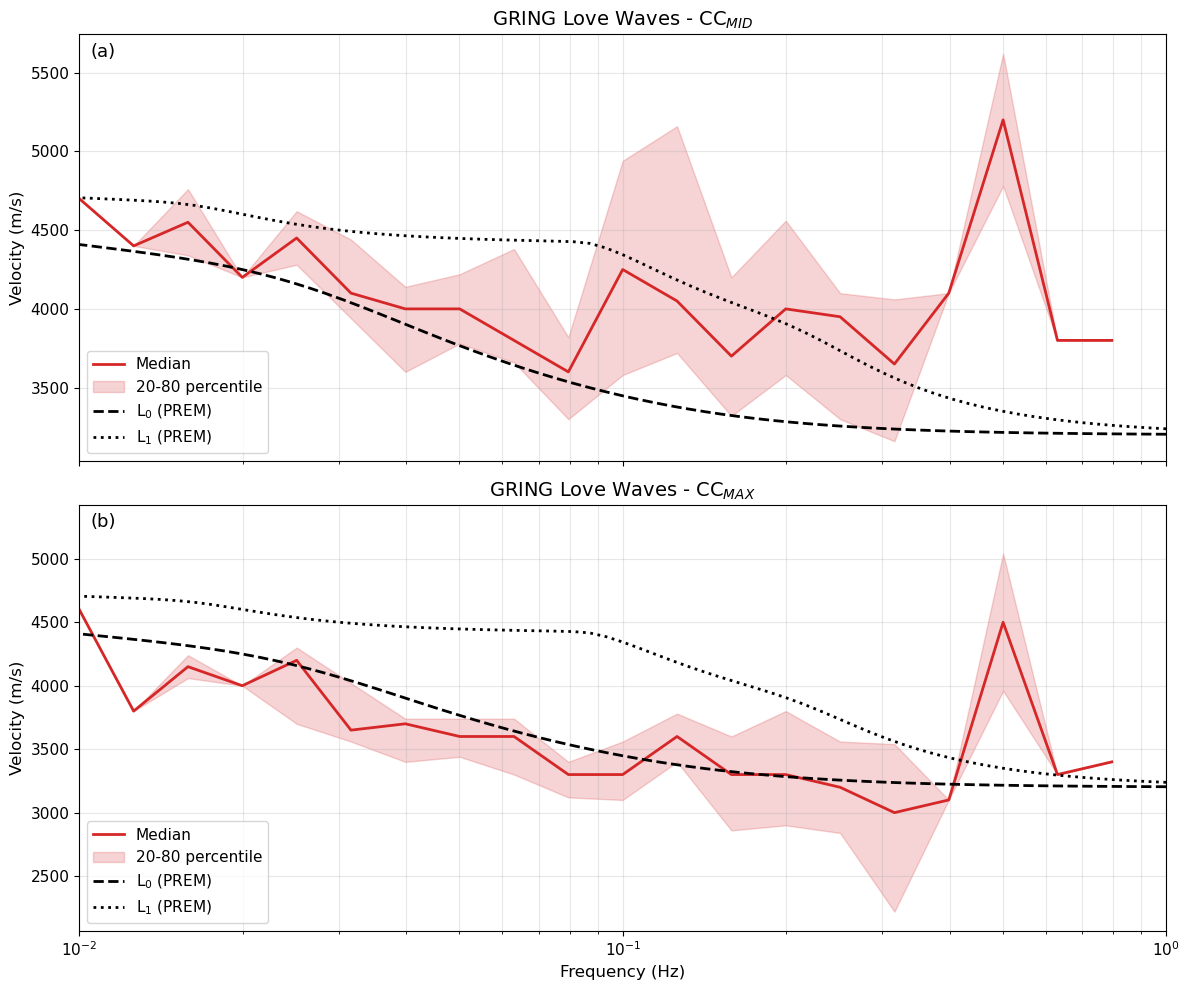

In [9]:
fig = plot_mid_max_vertical(
    merged=merged,
    ff_prem=ff_prem,
    L0_prem=L0_prem,
    L1_prem=L1_prem,
    show_event_curves=False
)

os.makedirs("./output/figures/publication", exist_ok=True)
fig.savefig("./output/figures/publication/dispersion_gring_love_mid_max.png", dpi=200, bbox_inches="tight")